# Pipeline improvement: the legacy `public` archive against the current `main`

VAFT's reconstructions have been rebuilt since the pre-VAFT pipeline archived its results in the
shot-first FileDB `public/<shot>/` (EFIT with legacy weights, CHEASE, DCON/RDCON). This notebook
scores **both pipelines with the same validation kernels** and asks, check by check, how much the
current pipeline (HSDS `main`, EFIT preset `statistical_891`, the stability atlas) differs from
the archive.

The five checks follow the validation scheme, from the input data to the downstream results:

| # | check | question | metric (same code on both sides) |
|---|---|---|---|
| 1 | magnetics vs vacuum model | is the *input* consistent with the coil + wall response before the plasma? | per-channel residual / dynamic range, plasma-free window |
| 2 | measured vs reconstructed | how well does the reconstruction reproduce its own constraints? | m-file relative RMS of $m-r$ per family |
| 3 | volume integral vs virial | is the equilibrium physically self-consistent? | $\ln(\beta_{p,\mathrm{int}}/\beta_{p,\mathrm{vir}})$, $\ln(l_{i}/l_{i,\mathrm{vir}})$, GS residual |
| 4 | Thomson vs EFIT pressure | does it agree with an independent diagnostic? | $\ln(\sum p_e/\sum p_\mathrm{EFIT})$ at the Thomson channels |
| 5 | stability | how do the downstream $\delta W$ and $\Delta'$ populations change? | DCON $W_t$, RDCON $\Delta'_{\max}$ |

**Data.** The tables were built by `workflow/pipeline_improvement/build_comparison_tables.py` on
vestserver and merged by `make_snapshot.py`; the snapshot is checked in under
`notebooks/data/pipeline_improvement_public_vs_main/` (its `snapshot_manifest.json` records the
sources, row counts and SHA-256). Point `VAFT_PIPELINE_COMPARISON_DIR` at a newer snapshot to
redraw everything. No database access is needed to run this notebook.

In [ ]:
import json
import os
from pathlib import Path

try:
    _ipython = get_ipython()
except NameError:
    _ipython = None
if _ipython is None:
    os.environ.setdefault("MPLBACKEND", "Agg")
elif "IPKernelApp" in _ipython.config:
    _ipython.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vaft.plot.pipeline_comparison import (
    pipeline_comparison_distribution,
    pipeline_comparison_measured_vs_reconstructed,
    pipeline_comparison_onset_population,
    pipeline_comparison_onset_scatter,
    pipeline_comparison_onset_traces,
    pipeline_comparison_overview,
    pipeline_comparison_paired,
    pipeline_comparison_quality_checks,
    pipeline_comparison_scorecard,
    pipeline_comparison_thomson,
)
from vaft.validation.pipeline_comparison import METRICS, pair_slices, paired_summary, population_summary

_repo_root = Path.cwd()
if _repo_root.name == "notebooks":
    _repo_root = _repo_root.parent
DATA = Path(os.environ.get("VAFT_PIPELINE_COMPARISON_DIR",
                           _repo_root / "notebooks" / "data" / "pipeline_improvement_public_vs_main")).expanduser()
OUTPUT_DIR = Path(os.environ.get("VAFT_DOCS_OUTPUT_DIR", _repo_root / "notebooks" / "outputs" / "docs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.size"] = 10


def table(name):
    path = DATA / f"{name}.csv.gz"
    return pd.read_csv(path, low_memory=False) if path.exists() else None


slices, fit, virial, thomson = (table(n) for n in ("slices", "fit", "virial", "thomson"))
points, vacuum = table("constraint_points"), table("vacuum_by_family")
legacy_stability, legacy_surfaces = table("stability_legacy"), table("stability_legacy_surfaces")
atlas = table("stability_current_atlas_n")
manifest = json.loads((DATA / "snapshot_manifest.json").read_text())
print(f"snapshot {manifest['created']}: " + ", ".join(
    f"{name.split('.')[0]} {entry['rows']}" for name, entry in manifest["files"].items() if entry.get("rows")))

SUMMARIES = []  # one paired summary per scored metric, for the scorecard


def paired_columns(frame, metric, key="pair_id", by="side"):
    # legacy and current values of one metric on the slices paired by time
    wide = frame[frame[key].notna()].pivot_table(index=key, columns=by, values=metric, aggfunc="first")
    wide = wide.apply(pd.to_numeric, errors="coerce")
    return wide.reindex(columns=["legacy", "current"])


def score(frame, metric, *, label=None, key="pair_id", by="side"):
    wide = paired_columns(frame, metric, key=key, by=by)
    summary = paired_summary(wide["legacy"], wide["current"], better=METRICS[metric]["better"])
    summary.update(metric=metric, label=label or METRICS[metric]["label"], check=METRICS[metric]["check"])
    SUMMARIES.append(summary)
    low, high = summary["shift_ci"]
    print(f"{summary['label']}: {summary['n_pairs']} pairs, median legacy {summary['legacy_median']:.3g} -> "
          f"current {summary['current_median']:.3g}, shift {summary['shift_median']:.3g} "
          f"[{low:.3g}, {high:.3g}], improved {summary['improved_fraction']:.0%}, "
          f"Wilcoxon p = {summary['wilcoxon_p']:.2g}; {summary['n_dropped']} pairs dropped (not finite on a side)")
    return summary


snapshot 2026-10-30T14:31:16+00:00: slices 12905, fit 12905, virial 12905, thomson 1759, thomson_channels 774, constraint_points 50639, vacuum_by_family 40100, onset 355872, onset_points 189384, onset_qa 50840, onset_traces 68640, stability_legacy 24084, stability_legacy_surfaces 50956


## 0. Which slices are compared

*Current* means what HSDS `main` publishes: a current EFIT slice is kept only when its time is in
`main`'s equilibrium. Each legacy slice is paired with the nearest current slice within 0.5 ms,
one to one (`pair_slices`), never by position. The two pipelines chose their own times, so many
slices have no partner. They stay in the per-side distributions; only the pairs enter the paired
statistics.

**Selection bias.** The archive holds whatever the legacy pipeline produced; `main` holds only
slices that passed the current pipeline's own gates. A per-side distribution therefore mixes the
improvement with a change in *which* slices survive. The paired view, on the same shot and time,
is the like-for-like comparison.

In [ ]:
per_side = slices[slices["side"].notna()]
funnel = pd.DataFrame({
    "shots": per_side.groupby("side")["shot"].nunique(),
    "slices": per_side.groupby("side").size(),
    "paired slices": per_side[per_side["pair_id"].notna()].groupby("side").size(),
}).reindex(["legacy", "current"])
print(funnel.to_string())
print(f"\nshots with a pair: {per_side.loc[per_side['pair_id'].notna(), 'shot'].nunique()}; "
      f"median |dt| of a pair: {1e3 * per_side['pair_offset_s'].abs().median():.3f} ms")


         shots  slices  paired slices
side                                 
legacy    1238    4071           2794
current   1472    8834           2794

shots with a pair: 1047; median |dt| of a pair: 0.000 ms


## 1. Magnetics against the vacuum model (input accuracy)

Before the plasma starts, the measured probes and flux loops should follow the field of the PF
coils and the induced wall currents alone. `synthetic_vacuum_magnetics` forward-models that
response at every channel; the metric is the RMS of measured minus model over the plasma-free
window, divided by the channel's dynamic range (`vacuum_residual_metrics`). This check does not
involve EFIT: it scores the **processed magnetics and PF currents** each pipeline stored.

Two wall models are reported:

- `stored`: each product's own passive-loop currents;
- `common_2303`: the wall re-solved from the PF currents alone with one resistance vintage on both
  sides (`benchmark_wall_currents`), on the current product's coil and wall geometry. What is
  left differs only by the measured magnetics and PF currents.

Only channels both products evaluated enter the medians (one row per shot and channel family).

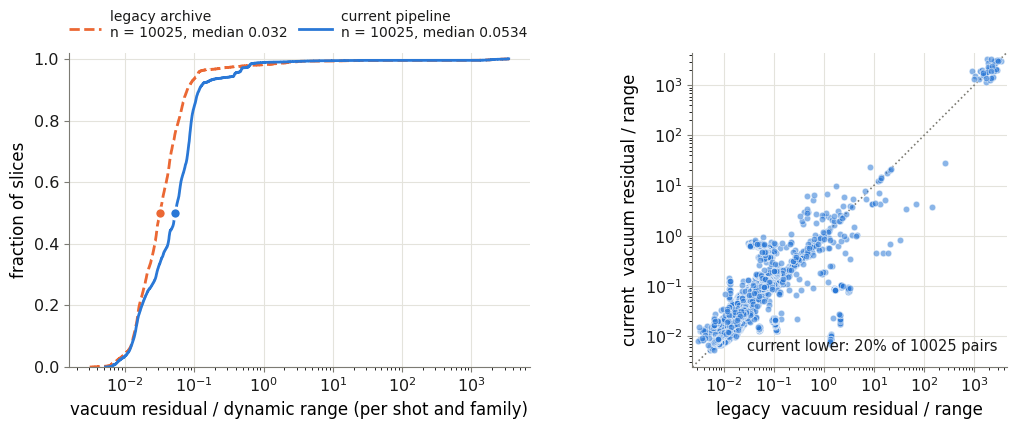

vacuum residual / dynamic range: 10025 pairs, median legacy 0.032 -> current 0.0534, shift 0.0163 [0.0146, 0.0181], improved 20%, Wilcoxon p = 0; 0 pairs dropped (not finite on a side)

median per family (common wall model):
side                legacy  current  current / legacy
family                                               
inboard             0.0460   0.0879            1.9098
inboard_flux_loop   0.0225   0.0240            1.0706
outboard            0.0489   0.0699            1.4311
outboard_flux_loop  0.0171   0.0160            0.9409
side                0.0349   0.0532            1.5226

median with each product's stored wall currents:
        normalized_residual_median
source                            
main                        0.0531
public                      0.0323


In [ ]:
common = vacuum[vacuum["wall_model"] == "common_2303"].copy()
common["side"] = common["source"].map({"public": "legacy", "main": "current"})
common["pair_id"] = common["shot"].astype(str) + ":" + common["family"]
common = common.rename(columns={"normalized_residual_median": "vacuum_normalized_residual"})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
pipeline_comparison_distribution(common, "vacuum_normalized_residual", log=True,
                                 xlabel="vacuum residual / dynamic range (per shot and family)", ax=axes[0])
pipeline_comparison_paired(common, "vacuum_normalized_residual", log=True,
                           label="vacuum residual / range", ax=axes[1])
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pipeline-improvement-vacuum.png", dpi=180, bbox_inches="tight")
plt.show()
score(common, "vacuum_normalized_residual")

by_family = common.pivot_table(index="family", columns="side", values="vacuum_normalized_residual",
                               aggfunc="median").reindex(columns=["legacy", "current"])
by_family["current / legacy"] = by_family["current"] / by_family["legacy"]
print("\nmedian per family (common wall model):\n" + by_family.round(4).to_string())
stored = vacuum[vacuum["wall_model"] == "stored"].pivot_table(
    index="source", values="normalized_residual_median", aggfunc="median")
print("\nmedian with each product's stored wall currents:\n" + stored.round(4).to_string())


### 1b. Measured against vacuum, aligned at the plasma onset

The same forward model as a function of time, on one clock per shot: $t - t_\mathrm{onset}$, with
$t_\mathrm{onset}$ the plasma-free boundary of the `main` product (`plasma_free_boundary`; `public`'s
when `main` has none) used for **both** sides, so a side whose timing is off shows as a shifted
trace instead of being realigned out of sight. Each side keeps its own stored wall currents.

- Probes and flux loops: per shot, the median over channels of $|m - m_\mathrm{vac}|$ over the
  channel's largest $|m|$ before the onset. Before the onset this is the vacuum model's error; after
  it, the plasma's own signal.
- Plasma current: the measured $I_p$. It has no vacuum model; the compensated current is expected
  to be zero before the onset, which is the dashed line.

The population is every sixth shot of the vacuum check (380 shots; the 45 without a plasma onset on
either side, vacuum shots, drop out). Three shots keep every channel's trace. The second figure
shows one of them with the typical channel of each family: the one whose residual before the onset
is the family's median.

337 shots; 0 source-shots failed the forward model


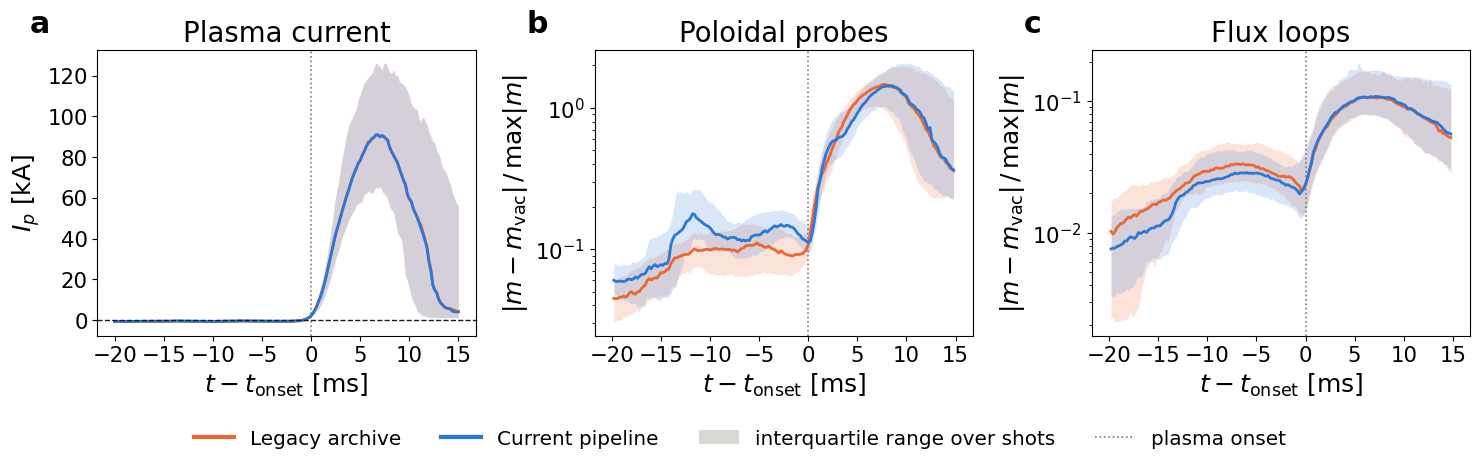

side                             current  legacy
family phase                                    
loop   after onset (0..15 ms)      0.084   0.082
       before onset (-15..0 ms)    0.023   0.028
probe  after onset (0..15 ms)      0.802   0.818
       before onset (-15..0 ms)    0.130   0.094


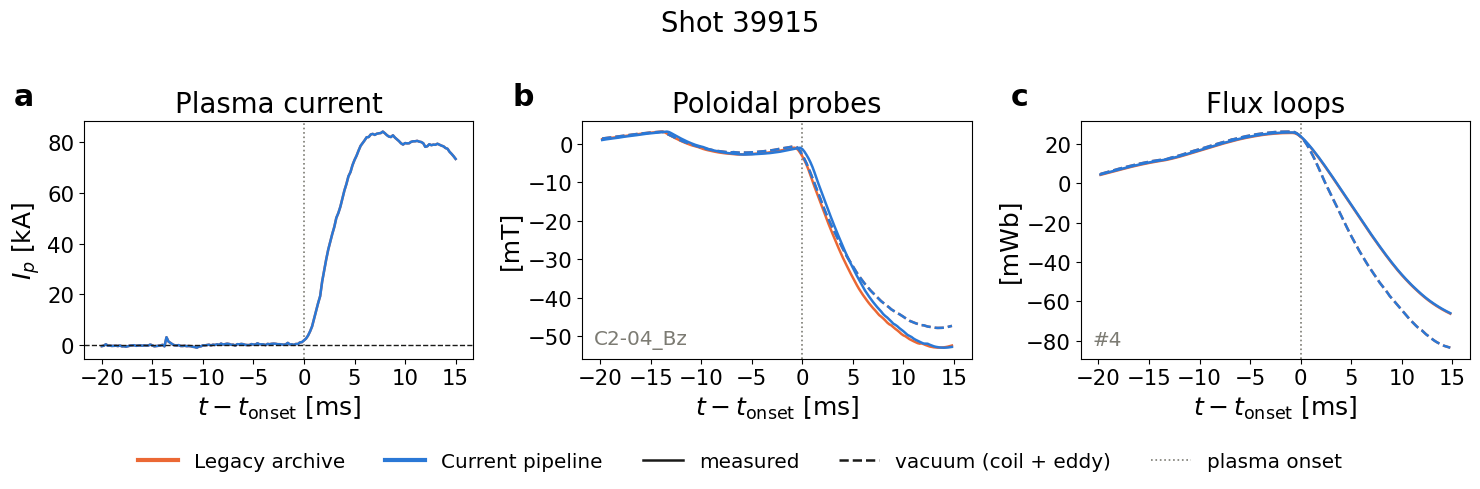

In [ ]:
onset = pd.read_csv(DATA / "onset.csv.gz")
onset_traces = pd.read_csv(DATA / "onset_traces.csv.gz")
onset_errors = onset[onset["family"] == "error"]
onset = onset[onset["family"] != "error"]
print(f"{onset['shot'].nunique()} shots; {onset_errors['shot'].nunique()} source-shots failed the forward model")

fig, axes = pipeline_comparison_onset_population(onset)
fig.savefig(OUTPUT_DIR / "pipeline-improvement-onset.png", dpi=180, bbox_inches="tight")
plt.show()

window = onset[onset["family"].isin(["probe", "loop"])].assign(
    phase=lambda t: np.where(t["t_ms"] < 0, "before onset (-15..0 ms)", "after onset (0..15 ms)"))
window = window[window["t_ms"].between(-15, 15)]
print(window.assign(side=window["source"].map({"public": "legacy", "main": "current"}))
      .groupby(["family", "phase", "side"])["value"].median().unstack().round(3).to_string())

fig, axes = pipeline_comparison_onset_traces(onset_traces, shot=39915)
plt.show()

The same comparison as a scatter in the layout of the fit overview: every channel's measured value
against the vacuum model at $t - t_\mathrm{onset} = -1$ ms. Each point carries the verdict of the
**input QA** (`validate_magnetics_signals`, #189), run afresh on both products so both sides are
judged by one detector; a cross is a channel it rejects (invalid or suspect at that instant). The
input QA judges the waveform alone, never its agreement with the model, so crosses far from $y = x$
are sensors it already caught and dots far from it are ones it did not. The vacuum model gives the
plasma current no value but zero, so in (a) the points sit on $y = 0$.

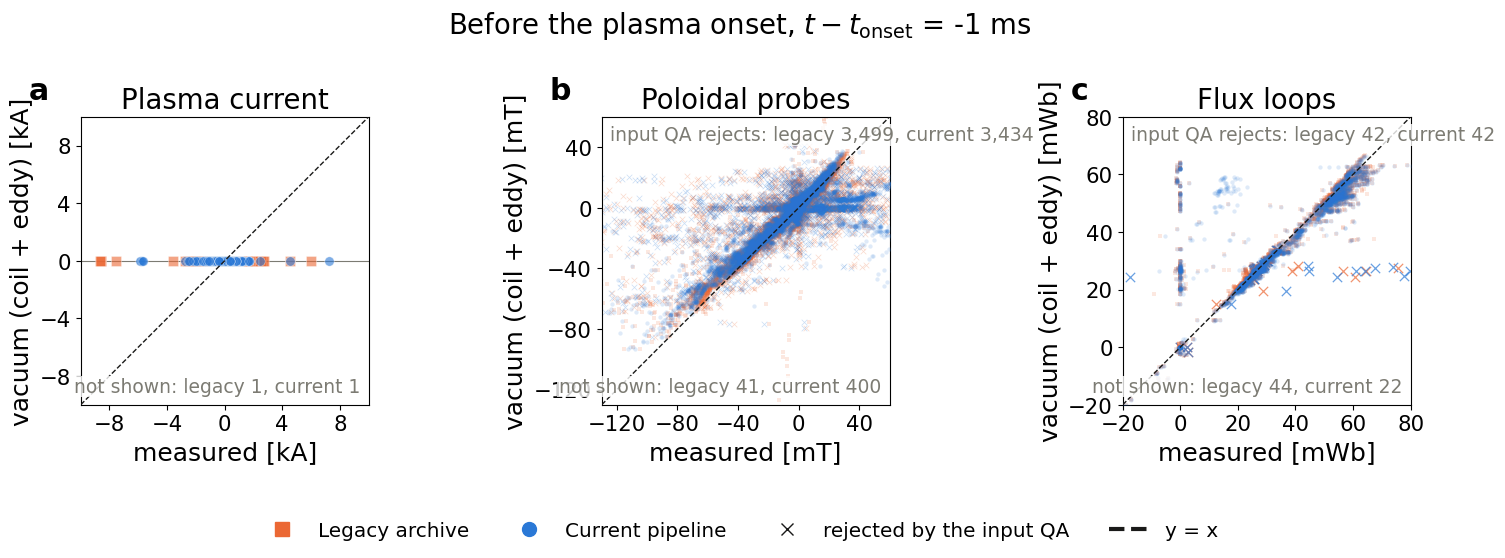

channels per input-QA verdict at -1 ms:
qa_code        -2.0    0.0   1.0
family source                   
loop   main      42   3645    20
       public    42   3641    24
probe  main    3434  17770   172
       public  3499  17717   160

median |measured - vacuum| [SI] by verdict:
accepted          False     True 
family source                    
loop   main    0.001429  0.000783
       public  0.001472  0.000792
probe  main    0.019542  0.001947
       public  0.012637  0.001090


In [ ]:
onset_points = pd.read_csv(DATA / "onset_points.csv.gz")
onset_qa = pd.read_csv(DATA / "onset_qa.csv.gz")
onset_qa = onset_qa[onset_qa["family"] != "error"]
ONSET_SCATTER_LIMITS = {"ip": (-10, 10), "probe": (-130, 60), "loop": (-20, 80)}
fig, axes = pipeline_comparison_onset_scatter(onset_qa, t_ms=-1.0, limits_by_panel=ONSET_SCATTER_LIMITS)
fig.savefig(OUTPUT_DIR / "pipeline-improvement-onset-scatter.png", dpi=180, bbox_inches="tight")
plt.show()
judged = onset_qa[onset_qa["family"].isin(["probe", "loop"])].assign(
    error=lambda t: (t["measured"] - t["vacuum"]).abs(), accepted=lambda t: t["qa_code"] >= 0)
print("channels per input-QA verdict at -1 ms:\n"
      + judged.groupby(["family", "source"])["qa_code"].value_counts().unstack(fill_value=0).to_string())
print("\nmedian |measured - vacuum| [SI] by verdict:\n"
      + judged.groupby(["family", "source", "accepted"])["error"].median().unstack().to_string())

## 2. Measured against reconstructed (fit accuracy)

Both sides are read from their EFIT m-files with one function (`magnetic_fit` of the EFIT
numerics study): for each family, the RMS of measured minus reconstructed over the channels the
fit used, divided by the RMS of the measurements. This is in the channels' own units, so it means
the same thing under the legacy weights and under the calibrated statistical sigma, which a
chi-square would not.

The two pipelines did not fit the same channels: the current one leaves probes on the broken
list out, the legacy one fitted all 64. A fit over fewer, cleaner channels scores better without
fitting better, so the **scored** metric uses only the channels *both* m-files of a pair fitted
(`common_channel_fit`); the distributions show each fit over its own channels.

The legacy fits pinned the plasma current with a very large weight, so their $I_p$ error is
essentially zero by construction; the diamagnetic flux carried a negligible weight. Those two are
shown for completeness and are not counted as improvements or regressions.

**Where the QA criteria sit in the overview.** The gray band is drawn only where a criterion of
`vaft.validation._efit_study_criteria.CRITERIA` (v2) grades the plotted pair itself:

- (c) $\beta_p$: the virial check, $|\ln(\beta_p^\mathrm{int}/\beta_p^\mathrm{vir})| \le \ln 2$, is the band.
  A slice with $\beta_p \le 0$ already fails admissibility; it is among the slices counted as not shown.
- (d) $l_i$: no criterion grades it against its closure, only the plausibility bound $0 < l_i \le 3$, so
  there is no band.
- (a, b) probes and flux loops: the criterion is the slice's reduced $\chi^2$ in $[0.5, 2]$, a statistic over
  the slice's channels scaled by each channel's sigma, not a band around $y = x$. Drawing one would
  invent a criterion.

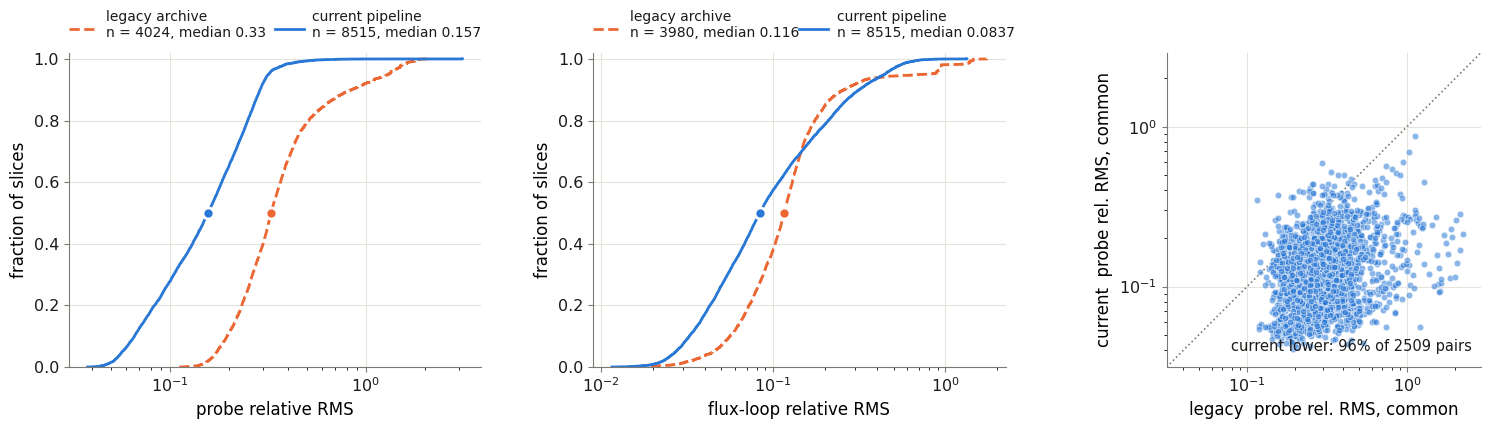

probe relative RMS, channels both fitted: 2509 pairs, median legacy 0.284 -> current 0.118, shift -0.158 [-0.164, -0.154], improved 96%, Wilcoxon p = 0; 0 pairs dropped (not finite on a side)
flux-loop relative RMS, channels both fitted: 2484 pairs, median legacy 0.113 -> current 0.0511, shift -0.0499 [-0.053, -0.0471], improved 84%, Wilcoxon p = 4.4e-253; 0 pairs dropped (not finite on a side)
probe |m - r| RMS / |m| RMS, each fit's own channels (not scored): median legacy 0.301, current 0.122
flux-loop |m - r| RMS / |m| RMS, each fit's own channels (not scored): median legacy 0.112, current 0.0601

median fitted channels per slice:
         probe_n  loop_n
side                    
current     60.0    11.0
legacy      64.0    10.0
|I_p,m - I_p,r| / |I_p,m| (not scored): median legacy 0, current 0.101
diamagnetic |m - r| / |m| (not scored): median legacy 1.97, current 0.177


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
pipeline_comparison_distribution(fit, "probe_relative_rms", log=True, xlabel="probe relative RMS", ax=axes[0])
pipeline_comparison_distribution(fit, "loop_relative_rms", log=True, xlabel="flux-loop relative RMS", ax=axes[1])
pipeline_comparison_paired(fit, "probe_relative_rms_common", log=True,
                           label="probe rel. RMS, common", ax=axes[2])
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pipeline-improvement-fit.png", dpi=180, bbox_inches="tight")
plt.show()
score(fit, "probe_relative_rms_common")
score(fit, "loop_relative_rms_common")
for metric in ("probe_relative_rms", "loop_relative_rms"):
    wide = paired_columns(fit, metric)
    print(f"{METRICS[metric]['label']}, each fit's own channels (not scored): median legacy "
          f"{wide['legacy'].median():.3g}, current {wide['current'].median():.3g}")
counts = fit.groupby("side")[["probe_n", "loop_n"]].median()
print("\nmedian fitted channels per slice:\n" + counts.to_string())
for metric in ("ip_relative_error", "dia_relative_error"):
    wide = paired_columns(fit, metric)
    print(f"{METRICS[metric]['label']} (not scored): median legacy {wide['legacy'].median():.3g}, "
          f"current {wide['current'].median():.3g}")


Measured against reconstructed in physical units, on paired slices only, legacy against current
by colour (the view of `equilibrium_quality_diagnostic_grid`). The upper row shows every fitted probe
and flux loop of a 400-slice subsample. The lower row shows $\beta_p$ and $l_i$ from volume integrals against the pair-13 virial closure (Section 3);
slices outside the view, including a non-positive $\beta_p$ on the log axis, are counted on each panel.
The plasma current and diamagnetic flux follow: the legacy fits pinned $I_p$ with a very large weight
and carried the diamagnetic flux with the opposite sign and a negligible weight.

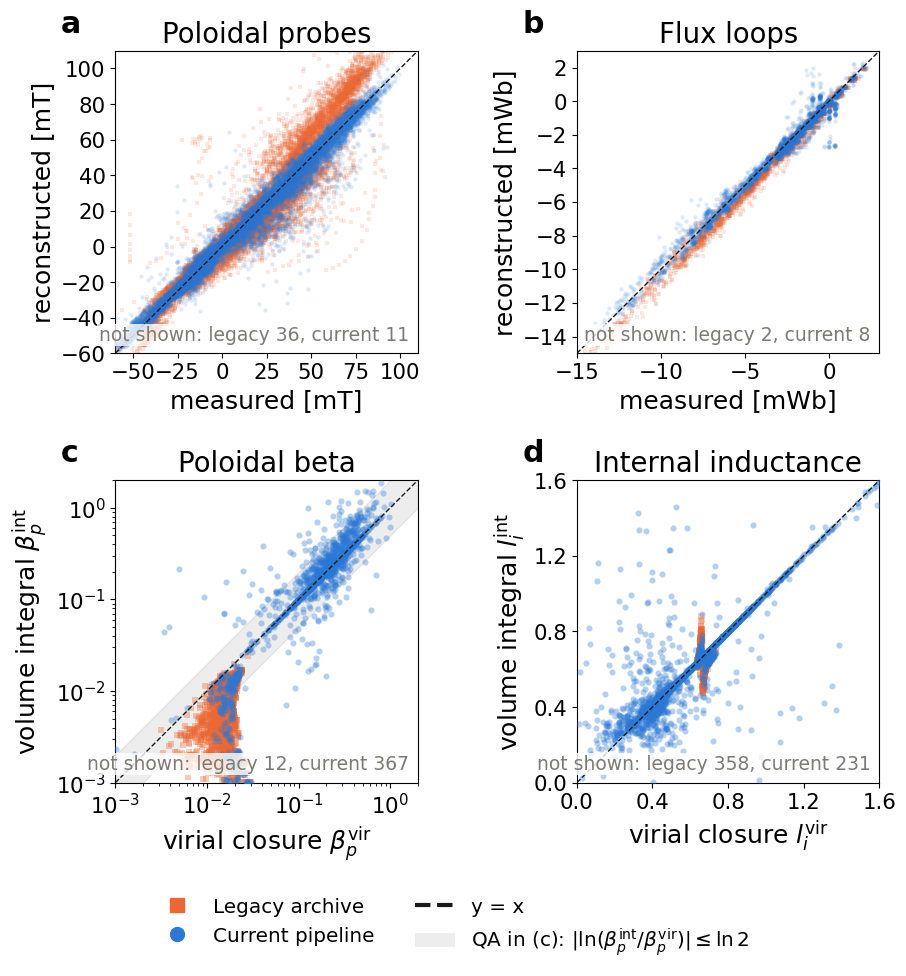

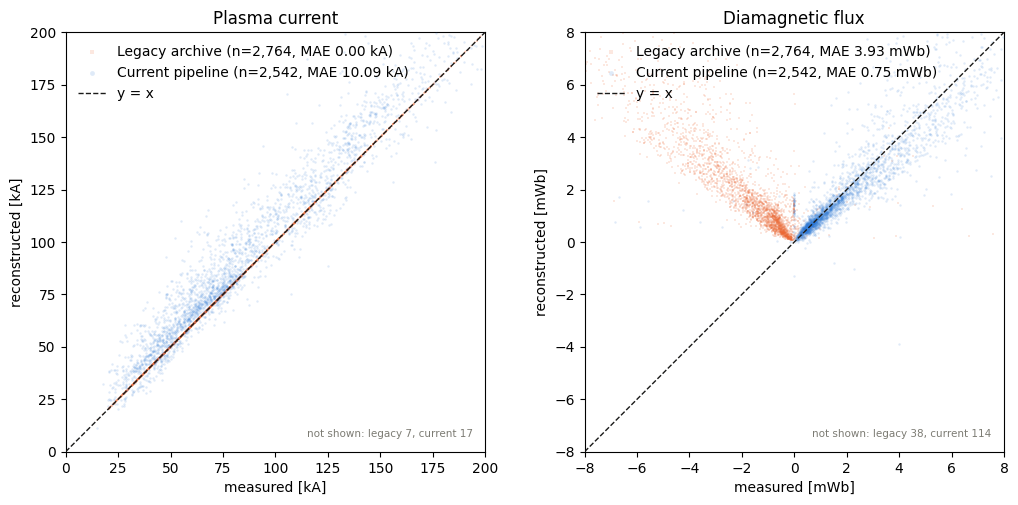

In [ ]:
paired_points = points[points["pair_id"].notna()]
paired_virial = virial[virial["pair_id"].notna()]
fig, axes = pipeline_comparison_overview(
    paired_points, paired_virial,
    limits_by_panel={"probe": (-60, 110), "loop": (-15, 3), "beta_p": (1e-3, 2.0), "li": (0.0, 1.6)})
fig.savefig(OUTPUT_DIR / "pipeline-improvement-overview.png", dpi=180, bbox_inches="tight")
plt.show()

paired_fit = fit[fit["pair_id"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.0))
pipeline_comparison_measured_vs_reconstructed(paired_fit, family="ip", ax=axes[0], limits=(0, 200))
pipeline_comparison_measured_vs_reconstructed(paired_fit, family="dia", ax=axes[1], limits=(-8, 8))
fig.tight_layout()
plt.show()

## 3. Volume integral against virial (physical consistency)

For a force-balanced equilibrium, $\beta_p$ and $l_i$ from volume integrals of the reconstructed
fields must agree with the Shafranov virial closure computed from the boundary (the #891 study's
`pair_13` closure; `compute_virial_equilibrium_quantities_ods` on the g-file, the same file on both
sides). The metric is the log ratio, so $0$ is perfect agreement and $\pm\ln 2$ a factor of two. The
Grad-Shafranov residual of the g-file is the force-balance error of the solution itself.

A slice whose volume-integral $\beta_p$ is not positive (a negative pressure somewhere in the
fit) has no ratio at all and drops out of the paired statistics. That is an admissibility
failure, not a pass, so the table after the figure counts it per side: the paired improvement
is only a statement about the slices that remain evaluable on both sides.

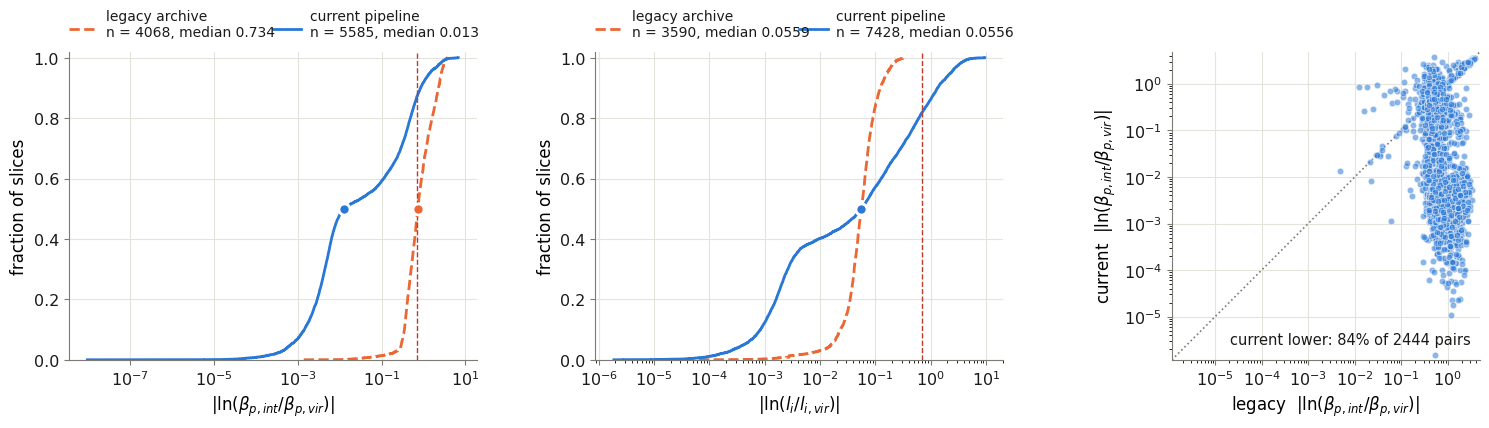

ln(beta_p,int / beta_p,virial): 2444 pairs, median legacy 0.712 -> current 0.00756, shift -0.61 [-0.635, -0.587], improved 84%, Wilcoxon p = 1.5e-278; 350 pairs dropped (not finite on a side)
ln(l_i,int / l_i,virial): 2328 pairs, median legacy 0.0563 -> current 0.00456, shift -0.034 [-0.0368, -0.0311], improved 65%, Wilcoxon p = 1.1e-17; 430 pairs dropped (not finite on a side)
Grad-Shafranov residual (whole): 2794 pairs, median legacy 0.0112 -> current 0.0171, shift 0.00211 [0.00137, 0.00282], improved 41%, Wilcoxon p = 9.8e-79; 0 pairs dropped (not finite on a side)

virial admissibility per side:
         slices  beta_p,int <= 0  within ln 2 (of evaluable)  within ln 2 (of all slices)
side                                                                                     
legacy     4071            0.000                       0.466                        0.465
current    8834            0.342                       0.871                        0.550
paired slices with beta_p,int <= 

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
pipeline_comparison_distribution(virial, "virial_log_ratio", better="zero", log=True,
                                 xlabel=r"ln($\beta_{p,int}/\beta_{p,vir}$)", ax=axes[0])
pipeline_comparison_distribution(virial, "li_log_ratio", better="zero", log=True,
                                 xlabel=r"ln($l_i/l_{i,vir}$)", ax=axes[1])
pipeline_comparison_paired(virial, "virial_log_ratio", better="zero", log=True,
                           label=r"ln($\beta_{p,int}/\beta_{p,vir}$)", ax=axes[2])
for ax in axes[:2]:
    ax.axvline(np.log(2.0), color="#c0392b", linewidth=1.0, linestyle="--")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pipeline-improvement-virial.png", dpi=180, bbox_inches="tight")
plt.show()
score(virial, "virial_log_ratio")
score(virial, "li_log_ratio")
score(virial, "gs_residual")
# A slice whose pressure integral is not positive has no virial ratio at all. It
# drops out of the paired statistics above, so it is counted here, per side.
beta_int = pd.to_numeric(virial["beta_p_integral"], errors="coerce")
ratio = pd.to_numeric(virial["virial_log_ratio"], errors="coerce")
admissibility = pd.DataFrame({
    "slices": virial.groupby("side").size(),
    "beta_p,int <= 0": (beta_int <= 0).groupby(virial["side"]).mean(),
    "within ln 2 (of evaluable)": (ratio.abs() <= np.log(2.0))[ratio.notna()].groupby(virial["side"]).mean(),
    "within ln 2 (of all slices)": (ratio.abs() <= np.log(2.0)).groupby(virial["side"]).mean(),
}).reindex(["legacy", "current"])
print("\nvirial admissibility per side:\n" + admissibility.round(3).to_string())
paired_beta = paired_columns(virial.assign(beta_p_integral=beta_int), "beta_p_integral")
print(f"paired slices with beta_p,int <= 0: legacy {(paired_beta['legacy'] <= 0).sum()}, "
      f"current {(paired_beta['current'] <= 0).sum()} of {len(paired_beta)}")


## 4. Thomson against EFIT pressure (independent diagnostic)

The Thomson electron pressure is the same measurement on both sides (HSDS `public`
`thomson_scattering`); only the reconstruction changes. `check_gfile` samples the reconstructed
pressure at each Thomson channel's flux surface at the nearest Thomson time and reports
$\ln(\sum p_e/\sum p_\mathrm{EFIT})$. With $T_i \le T_e$ and no fast ions the total pressure lies
between $p_e$ and $2p_e$, so the physical band is $[-\ln 2, 0]$. Few shots have Thomson, so this
sample is small.

The channel figure shades the same band, `thomson_log_ratio_band` of the QA criteria. Each point
carries a translucent horizontal bar of $2\sigma(p_e)$, with
$\sigma(p_e)/p_e = \sqrt{(\sigma_n/n_e)^2 + (\sigma_T/T_e)^2}$ from the stored `data_error_upper`
(taken as a symmetric $1\sigma$, the two independent; the lower arm stops at the axis). EFIT gives
$p_\mathrm{EFIT}$ no uncertainty, so there is no vertical bar.

status   indeterminate  not_available  pass  warn  error  fail
side                                                          
current             38            103     7    83      0     0
legacy               0             34     0     7      3    36


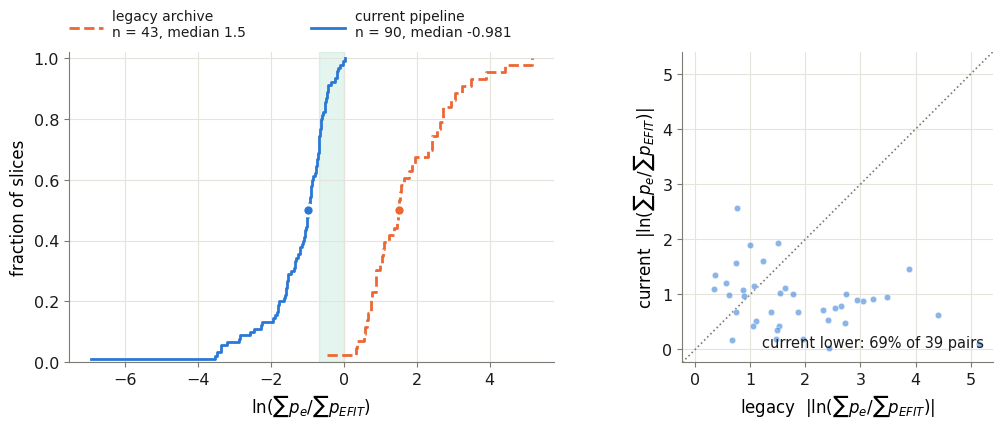

ln(sum p_e / sum p_EFIT): 39 pairs, median legacy 1.51 -> current 0.899, shift -0.76 [-1.72, -0.499], improved 69%, Wilcoxon p = 0.00023; 1 pairs dropped (not finite on a side)

fraction inside the physical band [-ln 2, 0]:
side
current    0.300
legacy     0.023


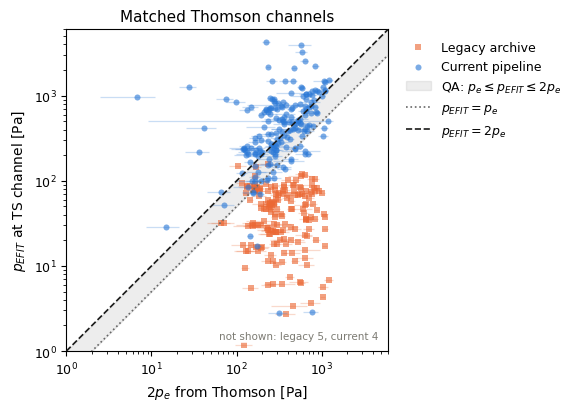


matched channels inside the band p_e <= p_EFIT <= 2 p_e:
          mean  size
side                
current  0.271   199
legacy   0.055   182


In [ ]:
thomson_scored = thomson[pd.to_numeric(thomson["thomson_log_ratio"], errors="coerce").notna()]
print(thomson.groupby(["side", "status"]).size().unstack(fill_value=0).to_string())
if len(thomson_scored):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    pipeline_comparison_distribution(thomson_scored, "thomson_log_ratio", better=None,
                                     xlabel=r"ln($\sum p_e / \sum p_{EFIT}$)", ax=axes[0])
    axes[0].axvspan(-np.log(2.0), 0.0, color="#1baf7a", alpha=0.12, zorder=0)
    pipeline_comparison_paired(thomson_scored, "thomson_log_ratio", better="zero",
                               label=r"ln($\sum p_e/\sum p_{EFIT}$)", ax=axes[1])
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "pipeline-improvement-thomson.png", dpi=180, bbox_inches="tight")
    plt.show()
    score(thomson_scored, "thomson_log_ratio")
    band = thomson_scored.assign(
        in_band=thomson_scored["thomson_log_ratio"].astype(float).between(-np.log(2.0), 0.0)
    ).groupby("side")["in_band"].mean()
    print("\nfraction inside the physical band [-ln 2, 0]:\n" + band.round(3).to_string())


# Channel by channel: EFIT pressure at each matched Thomson channel against 2 p_e.
channels = table("thomson_channels")
fig, ax = pipeline_comparison_thomson(channels, limits=(1.0, 6e3))
fig.savefig(OUTPUT_DIR / "pipeline-improvement-thomson-channels.png", dpi=180, bbox_inches="tight")
plt.show()
paired_channels = channels[channels["pair_id"].notna()].copy()
ratio = 2.0 * paired_channels["p_e"]
paired_channels["in_band"] = paired_channels["p_recon"].between(ratio / 2.0, ratio)
print("\nmatched channels inside the band p_e <= p_EFIT <= 2 p_e:\n"
      + paired_channels.groupby("side")["in_band"].agg(["mean", "size"]).round(3).to_string())

## 5. Stability: $\delta W$ and $\Delta'$

Legacy: the archive's `linear_stability/<ms>/{dcon,rdcon}/nn=<n>/` runs, read from their text
output (`read_dcon_text`, `read_pest3_matching_text`; the reader reproduces the netCDF $\Delta'$
diagonal of runs that wrote both within 0.6 %). Current: the Tier A stability atlas v2
(`magnetics-only` lineage, DCON full edge at mpsi 256, RDCON $\Delta'_{\max}$ over every surface).

These are physical results, not quality scores: a change in the unstable fraction is not by
itself better or worse. They differ for three reasons at once, the equilibrium, the solver
settings (legacy mpsi 128) and the slice selection (the atlas is 150 selected slices), so the
matched subset, same shot and time, is the closest like-for-like view.

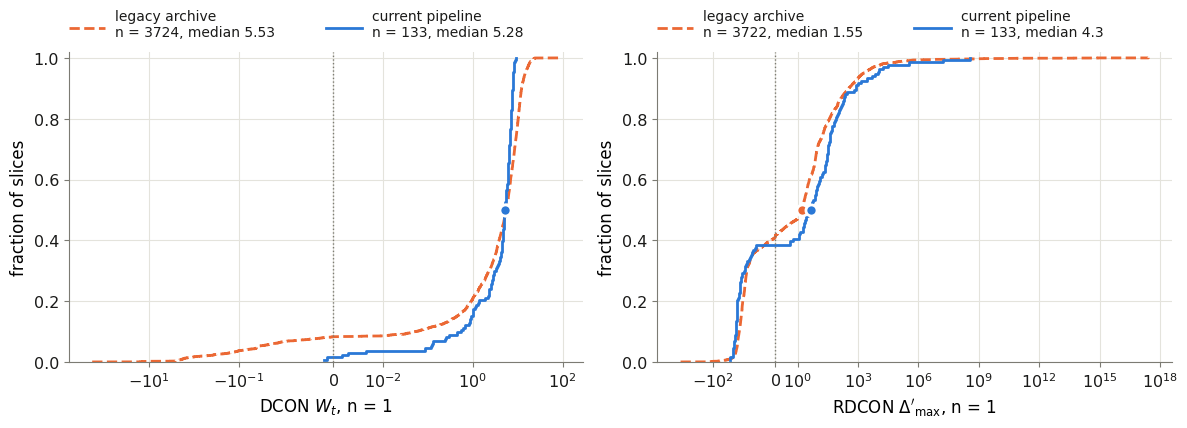

 n    side  W_t slices  ideal unstable (W_t < 0)  Delta' slices  tearing drive (Delta'_max > 0)
 1  legacy        3724                     0.083           3722                           0.583
 1 current         133                     0.015            133                           0.617
 2  legacy        3732                     0.050           3646                           0.365
 2 current         133                     0.015            133                           0.594
 3  legacy        3693                     0.050              0                             NaN
 3 current         133                     0.030              0                             NaN
 4  legacy        3673                     0.052              0                             NaN
 4 current         133                     0.038              0                             NaN
 5  legacy           0                       NaN              0                             NaN
 5 current         133                  

In [ ]:
legacy_dcon = legacy_stability[(legacy_stability["solver"] == "dcon") & (legacy_stability["status"] == "ok")]
legacy_rdcon = legacy_stability[(legacy_stability["solver"] == "rdcon") & (legacy_stability["status"] == "ok")]
current = atlas[atlas["efit_lineage"] == "magnetics-only"].copy()
current["time_ms"] = (1e3 * current["time_efit_s"]).round().astype(int)

w = pd.concat([
    legacy_dcon.assign(side="legacy")[["side", "shot", "time_ms", "n", "w_t"]],
    current.assign(side="current", n=current["n_tor"], w_t=current["dcon_full_256_W_t"])[
        ["side", "shot", "time_ms", "n", "w_t"]],
], ignore_index=True)
dp = pd.concat([
    legacy_rdcon.assign(side="legacy")[["side", "shot", "time_ms", "n", "delta_prime_max"]],
    current[current["n_tor"] <= 2].assign(side="current", n=current["n_tor"],
                                          delta_prime_max=current["rdcon_delta_prime_max_raw"])[
        ["side", "shot", "time_ms", "n", "delta_prime_max"]],
], ignore_index=True)

# matched subset: the same shot and millisecond on both sides
for frame in (w, dp):
    keys = frame.groupby(["shot", "time_ms", "n"])["side"].nunique()
    both = keys[keys == 2].index
    frame["pair_id"] = [f"{s}:{t}:{n}" if (s, t, n) in both else None
                        for s, t, n in zip(frame["shot"], frame["time_ms"], frame["n"])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
pipeline_comparison_distribution(w[w["n"] == 1], "w_t", better=None, linthresh=1e-2,
                                 xlabel="DCON $W_t$, n = 1", ax=axes[0])
pipeline_comparison_distribution(dp[dp["n"] == 1], "delta_prime_max", better=None, linthresh=1.0,
                                 xlabel=r"RDCON $\Delta'_{\max}$, n = 1", ax=axes[1])
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pipeline-improvement-stability.png", dpi=180, bbox_inches="tight")
plt.show()

rows = []
for n in sorted(w["n"].dropna().unique()):
    for side in ("legacy", "current"):
        values = w[(w["n"] == n) & (w["side"] == side)]["w_t"].astype(float)
        drive = dp[(dp["n"] == n) & (dp["side"] == side)]["delta_prime_max"].astype(float)
        rows.append({"n": int(n), "side": side, "W_t slices": len(values),
                     "ideal unstable (W_t < 0)": (values < 0).mean() if len(values) else np.nan,
                     "Delta' slices": len(drive),
                     "tearing drive (Delta'_max > 0)": (drive > 0).mean() if len(drive) else np.nan})
print(pd.DataFrame(rows).round(3).to_string(index=False))
matched = w[w["pair_id"].notna()]
print(f"\nmatched (shot, time, n) for W_t: {matched['pair_id'].nunique()}")
if matched["pair_id"].nunique():
    wide = paired_columns(matched, "w_t")
    agree = (np.sign(wide["legacy"]) == np.sign(wide["current"])).mean()
    print(f"sign of W_t agrees on {agree:.0%} of matched cases")


## 6. Scorecard

One line per scored metric: the median of the current pipeline over the median of the archive on
the paired slices (left of 1 is better), with the share of pairs that improved and the
two-sided Wilcoxon signed-rank p-value of the paired shift. Log-ratio metrics are compared by
magnitude. The stability results have no quality direction and are not on the scorecard.

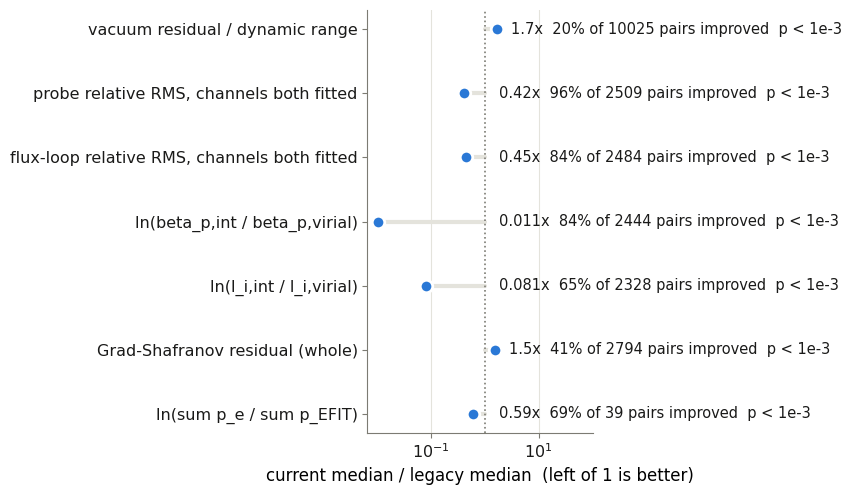

  check                                        label  n_pairs  legacy_median  current_median  shift_median  improved_fraction  wilcoxon_p
 vacuum              vacuum residual / dynamic range    10025          0.032          0.0534        0.0163              0.201           0
    fit     probe relative RMS, channels both fitted     2509          0.284           0.118        -0.158              0.957           0
    fit flux-loop relative RMS, channels both fitted     2484          0.113          0.0511       -0.0499              0.835   4.37e-253
 virial               ln(beta_p,int / beta_p,virial)     2444          0.712         0.00756         -0.61              0.838   1.49e-278
 virial                     ln(l_i,int / l_i,virial)     2328         0.0563         0.00456        -0.034              0.651    1.14e-17
 virial              Grad-Shafranov residual (whole)     2794         0.0112          0.0171       0.00211              0.414    9.82e-79
thomson                     ln(sum

In [ ]:
fig, ax = pipeline_comparison_scorecard(SUMMARIES)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pipeline-improvement-scorecard.png", dpi=180, bbox_inches="tight")
plt.show()
scorecard = pd.DataFrame(SUMMARIES)[["check", "label", "n_pairs", "legacy_median", "current_median",
                                      "shift_median", "improved_fraction", "wilcoxon_p"]]
print(scorecard.to_string(index=False, float_format=lambda v: f"{v:.3g}"))


## 7. Paper figure: four quality checks

One figure for the manuscript, one quality check per panel, legacy against current: (a) the input
check of §1b at $-1$ ms on the probes the input QA accepts (the rejects are left out), (b) the fit check of §2, (c) the
force-balance check of §3 with its QA band, (d) the consistency check of §4 with its QA band and
Thomson error bars. The counts the panels leave out are printed below for the caption.

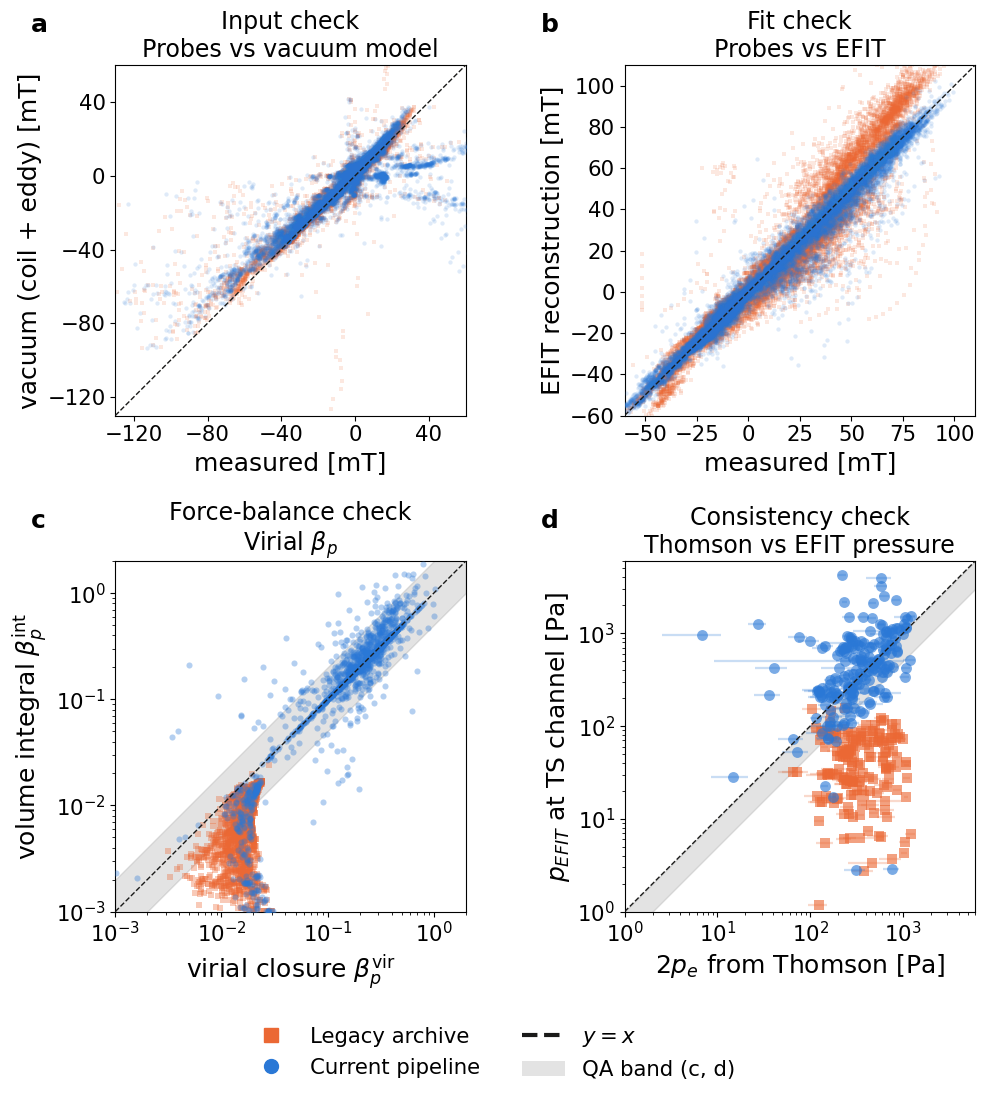

legacy: (a) 21,376 probes, 3,499 rejected by the input QA, 673 outside the view; (b) 23,291 probe points, 36 outside; (c) 2,794 slices, 12 outside or non-positive; (d) 182 channels, 5 outside or non-positive
current: (a) 21,376 probes, 3,434 rejected by the input QA, 1,158 outside the view; (b) 19,376 probe points, 11 outside; (c) 2,794 slices, 367 outside or non-positive; (d) 199 channels, 4 outside or non-positive


In [ ]:
fig, axes = pipeline_comparison_quality_checks(
    onset_qa, paired_points, paired_virial, channels,
    limits_by_panel={"onset": (-130, 60), "probe": (-60, 110), "beta_p": (1e-3, 2.0), "thomson": (1.0, 6e3)})
fig.savefig(OUTPUT_DIR / "pipeline-improvement-quality-checks.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "pipeline-improvement-quality-checks.pdf", bbox_inches="tight")
plt.show()


def outside(x, y, low, high, log=False):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y) & (x >= low) & (x <= high) & (y >= low) & (y <= high)
    return int((~ok).sum())


probe_qa = onset_qa[onset_qa["family"] == "probe"]
for side, source in (("legacy", "public"), ("current", "main")):
    a = probe_qa[probe_qa["source"] == source]
    b = paired_points[(paired_points["family"] == "probe") & (paired_points["side"] == side)]
    c = paired_virial[paired_virial["side"] == side]
    d = channels[channels["pair_id"].notna() & (channels["side"] == side)]
    print(f"{side}: (a) {len(a):,} probes, {int((a['qa_code'] < 0).sum()):,} rejected by the input QA, "
          f"{outside(a['measured'] * 1e3, a['vacuum'] * 1e3, -130, 60):,} outside the view; "
          f"(b) {len(b):,} probe points, {outside(b['measured'] * 1e3, b['reconstructed'] * 1e3, -60, 110):,} outside; "
          f"(c) {len(c):,} slices, {outside(c['beta_p_pair_13'], c['beta_p_integral'], 1e-3, 2.0):,} outside or non-positive; "
          f"(d) {len(d):,} channels, {outside(2 * d['p_e'], d['p_recon'], 1.0, 6e3):,} outside or non-positive")

## Reading the result

- **Paired, not pooled.** The scorecard uses only slices present on both sides at the same time;
  the per-side distributions above also carry the change in which slices exist at all.
- **Same kernels, different inputs.** Every metric is computed by one function on both sides from
  the same kind of file (m-file, g-file, HSDS diagnostics). Differences are the pipelines', not
  the scoring's.
- **Fit quality on common channels.** The scored fit metric uses only channels both pipelines
  fitted; the current pipeline's exclusion of broken probes is a real improvement too, but it is
  not counted as a better fit.
- **Current means what `main` publishes.** A FileDB g-file counts as current when its time is a
  `main` equilibrium time. A stale generation at the same time would pass this test; the FileDB
  stale-g-file scan of 2026-10-12 found none.
- **The vacuum check scores the input data, and the current side is worse.** With one wall model on
  both sides, the difference is in the stored magnetics. Two causes were traced (PR #2135): the current
  probe processing low-passes with a causal FIR filter, which delays every B-pol probe by 0.5 ms
  against the zero-phase PF currents (the legacy chain used `filtfilt`; reprocessing with it
  reproduces the stored `public` probes and halves the residual), and the products of 43685–46342
  still carry a superseded magnetics-processing override (#1731). Both need a production
  regeneration before this check can show the current pipeline's own accuracy.
- **Stability is reported, not scored.** $W_t$ and $\Delta'$ are physical results computed at
  different resolutions on differently selected slices; their populations are shown so that a
  change in the downstream picture is visible, not graded.
- **Provenance.** The legacy archive was read from the restored copy of the deleted
  `/srv/vest.filedb/public` (3dst-nas `vest_db_backup`); `snapshot_manifest.json` names every
  source.